# DermaGen · 01 — Exploration du jeu de données HAM10000

**Objectif :** comprendre les données avant de construire les modèles génératifs :

1. ce que contient le fichier de métadonnées ;
2. à quel point les classes sont déséquilibrées ;
3. combien de photos existent pour une même lésion ;
4. à quoi ressemblent les images, en taille réelle et en 28×28 ;
5. pourquoi le découpage train / test doit se faire **par lésion**.

Ce notebook ne modifie aucune donnée. Les figures sont enregistrées dans `results/figures/` pour le rapport.

## 0. Préparation

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/: go up one level to reach the project root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src import config, utils

config.ensure_dirs()
FIG = config.FIGURES_DIR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREY, RED = "#8a8a99", "#d4553a"   # red = rare classes targeted by the augmentation

print("Dossier des données :", config.RAW_DIR)
print("Métadonnées trouvées :", config.METADATA_CSV.is_file())

Dossier des données : C:\Users\Lenovo\Desktop\dermagen\data\raw
Métadonnées trouvées : False


## 1. Le fichier de métadonnées

Une ligne par image :

- `image_id` relie la ligne au fichier JPG ;
- `lesion_id` identifie la lésion photographiée ;
- `dx` est le diagnostic, c'est-à-dire **l'étiquette** à générer et à reconnaître.

In [3]:
meta = pd.read_csv(config.METADATA_CSV)
print(f"{len(meta)} lignes, {meta.shape[1]} colonnes")
meta.head()

10015 lignes, 7 colonnes


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [4]:
# Type, valeurs manquantes et valeurs distinctes de chaque colonne
pd.DataFrame({
    "type": meta.dtypes.astype(str),
    "manquantes": meta.isna().sum(),
    "« unknown »": (meta == "unknown").sum(),
    "distinctes": meta.nunique(),
})

,type,manquantes,« unknown »,distinctes
lesion_id,object,0,0,7470
image_id,object,0,0,10015
dx,object,0,0,7
dx_type,object,0,0,4
age,float64,57,0,18
sex,object,0,57,3
localization,object,0,234,15


## 2. Répartition des classes

On associe à chaque code `dx` un numéro de classe, dans l'ordre fixé une fois pour toutes dans `src/config.py` (ordre alphabétique : akiec = 0 … vasc = 6).

In [5]:
meta["label"] = meta["dx"].map(config.CLASS_TO_IDX)
assert meta["label"].notna().all(), "un code dx inconnu est présent"

counts = meta["dx"].value_counts().rename_axis("dx").reset_index(name="images")
counts["nom"] = counts["dx"].map(config.CLASS_NAMES_FR)
counts["%"] = (100 * counts["images"] / len(meta)).round(2)
counts

,dx,images,nom,%
0,nv,6705,Naevus mélanocytaire,66.95
1,mel,1113,Mélanome,11.11
2,bkl,1099,Kératose bénigne,10.97
3,bcc,514,Carcinome basocellulaire,5.13
4,akiec,327,Kératose actinique / carcinome intraépithélial,3.27
5,vasc,142,Lésion vasculaire,1.42
6,df,115,Dermatofibrome,1.15


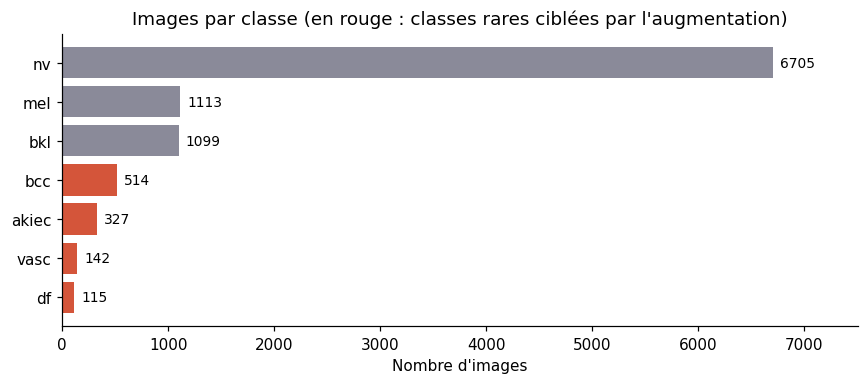

In [6]:
order = counts.sort_values("images")
colors = [RED if d in config.RARE_CLASSES else GREY for d in order["dx"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order["dx"], order["images"], color=colors)
for y, n in enumerate(order["images"]):
    ax.text(n + order["images"].max() * 0.01, y, f"{n}", va="center", fontsize=9)
ax.set_xlim(0, order["images"].max() * 1.12)
ax.set_xlabel("Nombre d'images")
ax.set_title("Images par classe (en rouge : classes rares ciblées par l'augmentation)")
fig.tight_layout()
fig.savefig(FIG / "01_class_distribution.png", dpi=150)
plt.show()

In [7]:
n_max, n_min = counts["images"].max(), counts["images"].min()
majority = counts.iloc[0]

print(f"Rapport entre la plus grande et la plus petite classe : {n_max / n_min:.0f}×")
print(f"Un modèle qui répond toujours « {majority['dx']} » obtient {majority['%']:.1f} % d'accuracy,")
print(f"mais seulement {100 / config.NUM_CLASSES:.1f} % de balanced accuracy (il ne reconnaît qu'une classe sur {config.NUM_CLASSES}).")

Rapport entre la plus grande et la plus petite classe : 58×
Un modèle qui répond toujours « nv » obtient 67.0 % d'accuracy,
mais seulement 14.3 % de balanced accuracy (il ne reconnaît qu'une classe sur 7).


**À retenir.** Avec un tel déséquilibre, l'accuracy est trompeuse : un modèle qui n'a rien appris obtient déjà un score élevé. On évaluera donc la classification avec la **balanced accuracy**, le **F1 macro** et le **rappel par classe**.

Les classes rares (akiec, bcc, df, vasc) sont celles où des images générées peuvent aider : c'est la question Q3 du projet.

## 3. Une lésion peut avoir plusieurs photos

Le même grain de beauté peut avoir été photographié plusieurs fois (autre jour, autre angle, autre zoom). Ces photos partagent le même `lesion_id`.

In [8]:
per_lesion = meta.groupby("lesion_id").size()

print(f"Images                 : {len(meta)}")
print(f"Lésions distinctes     : {per_lesion.size}")
print(f"Lésions avec 2+ photos : {(per_lesion > 1).sum()} ({100 * (per_lesion > 1).mean():.1f} % des lésions)")
print(f"Images concernées      : {per_lesion[per_lesion > 1].sum()} ({100 * per_lesion[per_lesion > 1].sum() / len(meta):.1f} % des images)")

per_lesion.value_counts().sort_index().rename_axis("photos par lésion").to_frame("lésions")

Images                 : 10015
Lésions distinctes     : 7470
Lésions avec 2+ photos : 1956 (26.2 % des lésions)
Images concernées      : 4501 (44.9 % des images)


,lésions
photos par lésion,
1,5514
2,1423
3,490
4,34
5,5
6,4


In [9]:
by_class = meta.groupby("dx").agg(images=("image_id", "size"), lesions=("lesion_id", "nunique"))
by_class["photos par lésion"] = (by_class["images"] / by_class["lesions"]).round(2)
by_class.loc[config.CLASSES]

,images,lesions,photos par lésion
dx,,,
akiec,327,228,1.43
bcc,514,327,1.57
bkl,1099,727,1.51
df,115,73,1.58
mel,1113,614,1.81
nv,6705,5403,1.24
vasc,142,98,1.45


10015 fichiers JPG trouvés
Images des métadonnées sans fichier : 0


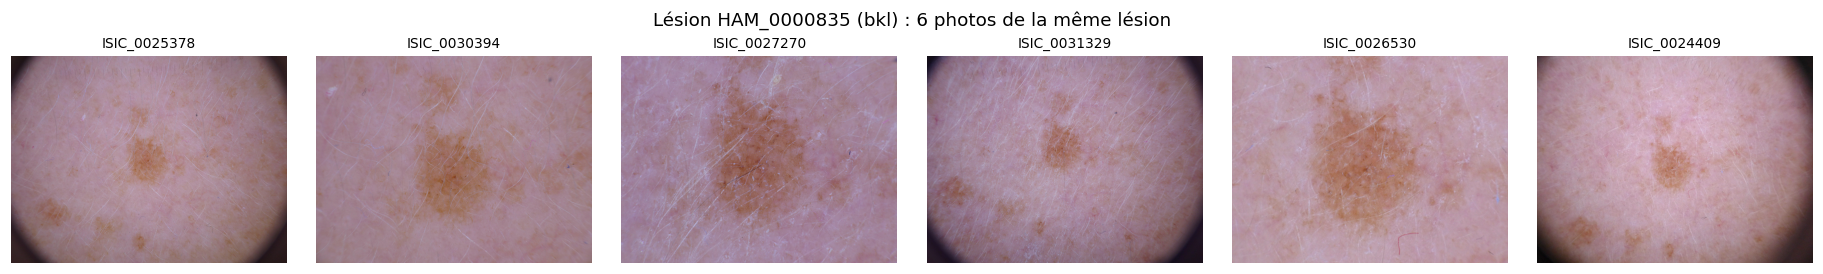

In [10]:
# Index of the JPG files: image_id -> path
paths = {p.stem: p
         for folder in sorted(config.RAW_DIR.glob(config.IMAGE_DIR_PATTERN))
         for p in folder.glob("*.jpg")}
print(f"{len(paths)} fichiers JPG trouvés")
missing = set(meta["image_id"]) - set(paths)
print(f"Images des métadonnées sans fichier : {len(missing)}")

# The lesion with the most photos
lesion = per_lesion.idxmax()
rows = meta[meta["lesion_id"] == lesion]
fig, axes = plt.subplots(1, len(rows), figsize=(2.8 * len(rows), 2.5))
for ax, (_, r) in zip(np.atleast_1d(axes), rows.iterrows()):
    ax.imshow(Image.open(paths[r["image_id"]]))
    ax.set_title(r["image_id"], fontsize=9)
    ax.axis("off")
fig.suptitle(f"Lésion {lesion} ({rows['dx'].iloc[0]}) : {len(rows)} photos de la même lésion")
fig.tight_layout()
plt.show()

## 4. Comment le diagnostic a été confirmé

- `histo` : analyse en laboratoire d'un prélèvement (histopathologie), la méthode la plus fiable ;
- `follow_up` : lésion suivie dans le temps sans changement ;
- `consensus` : avis concordant d'experts ;
- `confocal` : microscopie confocale.

In [11]:
pd.crosstab(meta["dx"], meta["dx_type"], margins=True, margins_name="total").loc[config.CLASSES + ["total"]]

dx_type,confocal,consensus,follow_up,histo,total
dx,,,,,
akiec,0,0,0,327,327
bcc,0,0,0,514,514
bkl,69,264,0,766,1099
df,0,60,0,55,115
mel,0,0,0,1113,1113
nv,0,503,3704,2498,6705
vasc,0,75,0,67,142
total,69,902,3704,5340,10015


## 5. Les patients

Les modèles génératifs n'utilisent pas ces colonnes, mais elles comptent pour la partie **limites** du rapport : les images ont été collectées à Vienne (Autriche) et dans le Queensland (Australie), donc certaines populations et couleurs de peau sont peu représentées.

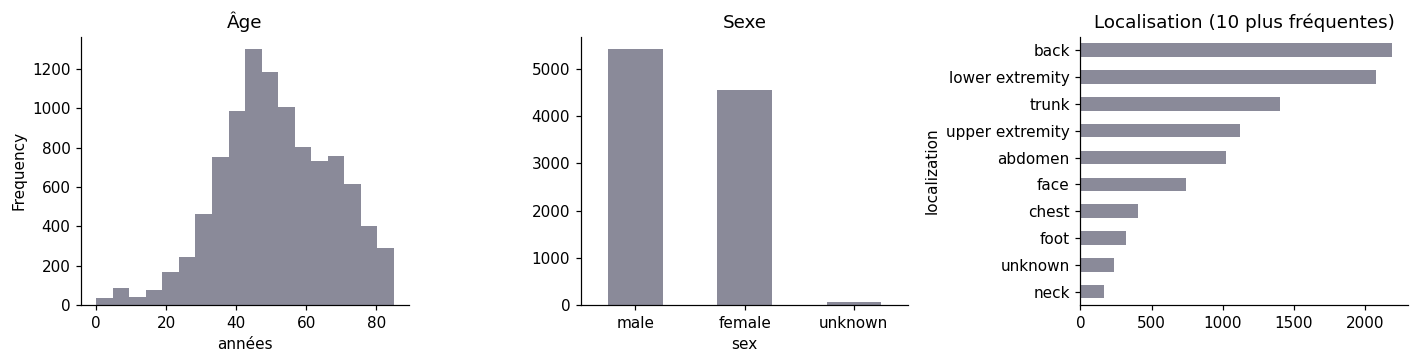

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
meta["age"].plot.hist(bins=18, ax=axes[0], color=GREY)
axes[0].set_title("Âge"); axes[0].set_xlabel("années")
meta["sex"].value_counts().plot.bar(ax=axes[1], color=GREY, rot=0)
axes[1].set_title("Sexe")
meta["localization"].value_counts().head(10).sort_values().plot.barh(ax=axes[2], color=GREY)
axes[2].set_title("Localisation (10 plus fréquentes)")
fig.tight_layout()
fig.savefig(FIG / "01_patients.png", dpi=150)
plt.show()

## 6. Les images

Les photos originales sont rectangulaires (format 4:3). Pour obtenir des images carrées de 28×28, deux options :

- **redimensionner directement** : l'image est écrasée horizontalement ;
- **recadrer au centre puis redimensionner** : les proportions sont gardées, et la lésion est presque toujours au centre de la photo.

On compare les deux visuellement.

In [13]:
sizes = pd.Series([Image.open(paths[i]).size for i in meta["image_id"].sample(200, random_state=0)])
sizes.value_counts().rename_axis("taille (largeur, hauteur)").to_frame("images (échantillon de 200)")

,images (échantillon de 200)
"taille (largeur, hauteur)",
"(600, 450)",200


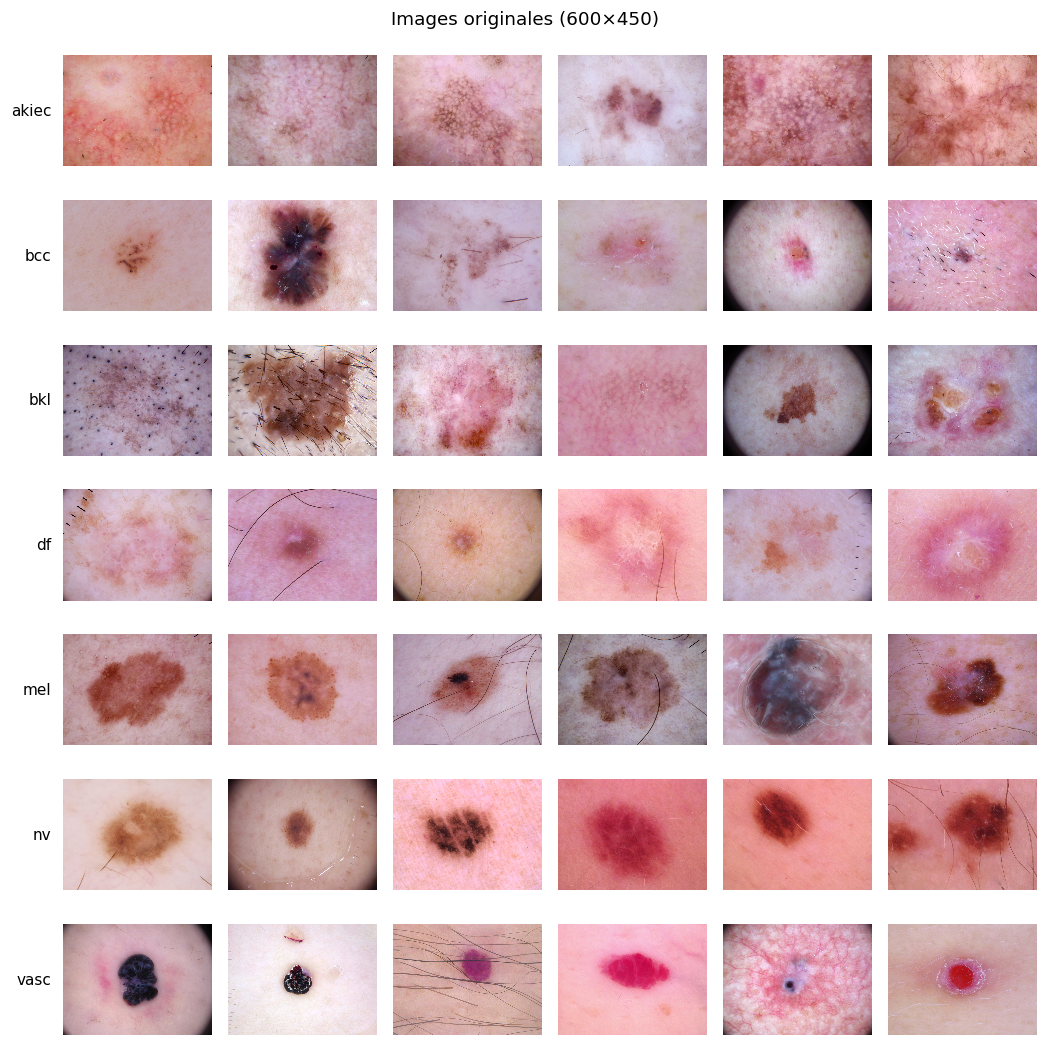

In [14]:
def to_small(img, size=28, crop=True):
    """Center-crop to a square (optional), then shrink to size×size."""
    if crop:
        w, h = img.size
        s = min(w, h)
        img = img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
    return img.resize((size, size), Image.LANCZOS)


N_COLS = 6
examples = meta.groupby("dx").sample(n=N_COLS, random_state=0)


def show_grid(transform, title, filename):
    fig, axes = plt.subplots(config.NUM_CLASSES, N_COLS,
                             figsize=(N_COLS * 1.6, config.NUM_CLASSES * 1.4))
    for r, dx in enumerate(config.CLASSES):
        ids = examples.loc[examples["dx"] == dx, "image_id"].tolist()
        for c in range(N_COLS):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(ids):
                ax.imshow(transform(Image.open(paths[ids[c]]).convert("RGB")), interpolation="nearest")
        axes[r, 0].text(-0.08, 0.5, dx, transform=axes[r, 0].transAxes,
                        ha="right", va="center", fontsize=10)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG / filename, dpi=150, bbox_inches="tight")
    plt.show()


show_grid(lambda im: im, "Images originales (600×450)", "01_examples_original.png")

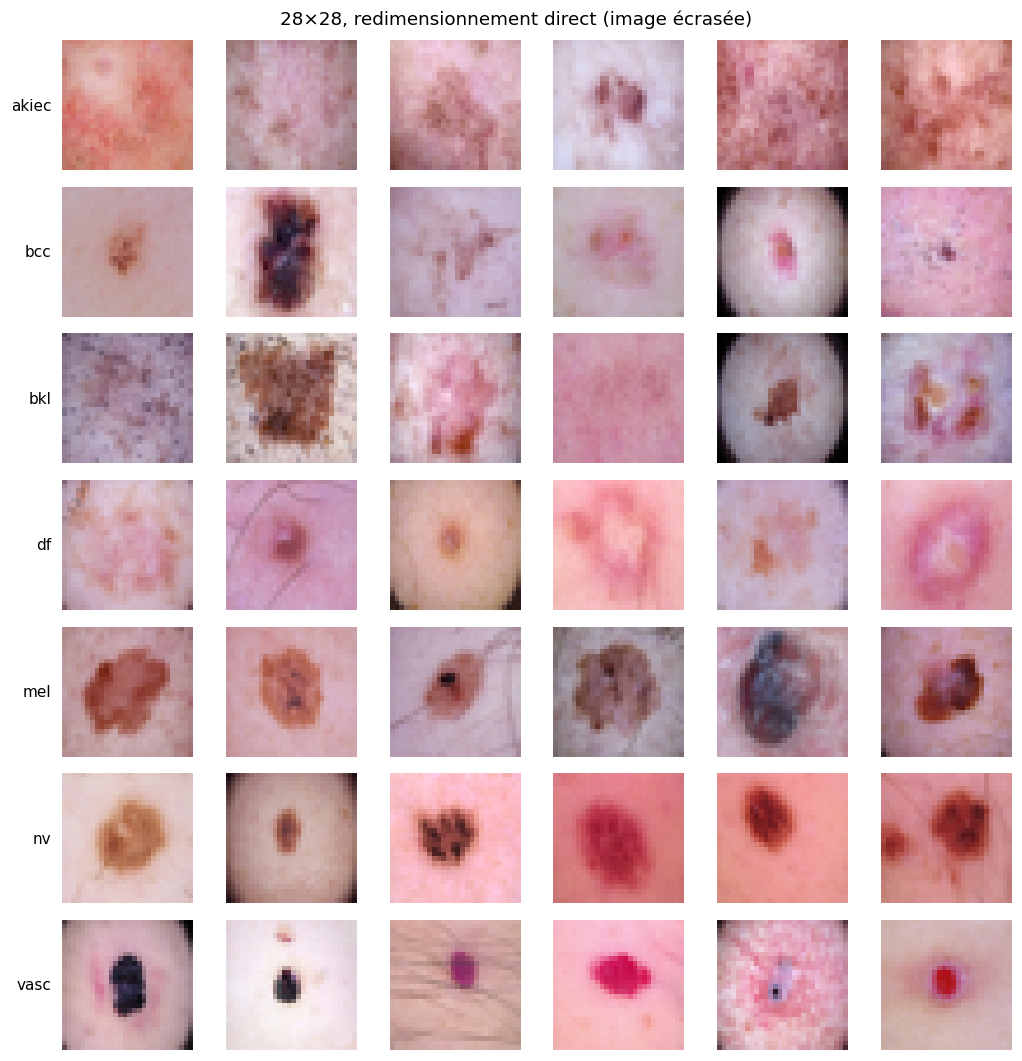

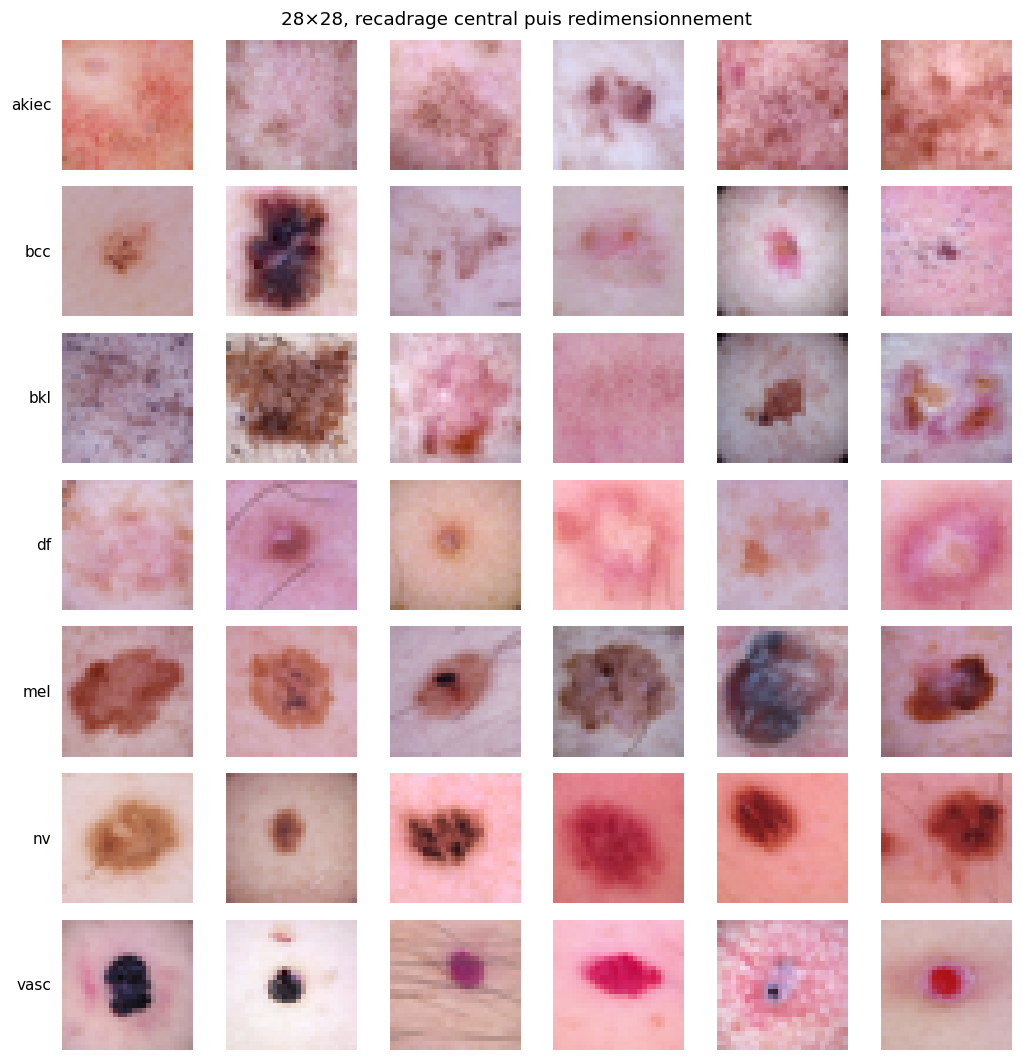

In [15]:
show_grid(lambda im: to_small(im, crop=False), "28×28, redimensionnement direct (image écrasée)", "01_examples_28_direct.png")
show_grid(lambda im: to_small(im, crop=True), "28×28, recadrage central puis redimensionnement", "01_examples_28_crop.png")

**Choix retenu :** recadrage central puis redimensionnement. Les proportions de la lésion sont conservées, et c'est ce que fera `src/prepare_data.py`.

La couleur est gardée (3 canaux) : en dermatologie, elle porte de l'information. Le graphique suivant le vérifie avec la couleur moyenne de chaque classe.

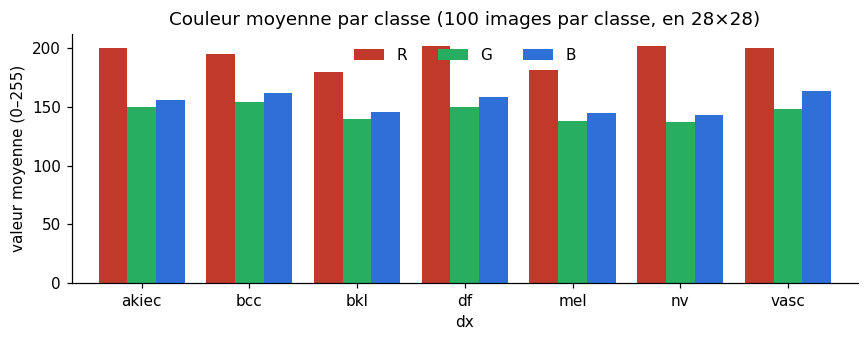

,R,G,B
dx,,,
akiec,200.1,149.8,156.1
bcc,194.8,154.4,161.5
bkl,180.0,139.3,145.6
df,201.5,150.1,158.5
mel,181.5,138.3,144.5
nv,201.8,137.2,142.7
vasc,199.8,148.3,163.4


In [16]:
sample = meta.groupby("dx").sample(n=100, random_state=1)
rgb = np.stack([np.asarray(to_small(Image.open(paths[i]).convert("RGB"))).reshape(-1, 3).mean(0)
                for i in sample["image_id"]])
mean_rgb = (pd.DataFrame(rgb, columns=["R", "G", "B"])
            .assign(dx=sample["dx"].to_numpy())
            .groupby("dx").mean().loc[config.CLASSES].round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
mean_rgb.plot.bar(ax=ax, color=["#c0392b", "#27ae60", "#2e6fd8"], rot=0, width=0.8)
ax.set_ylabel("valeur moyenne (0–255)")
ax.set_title("Couleur moyenne par classe (100 images par classe, en 28×28)")
ax.legend(ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "01_mean_colour.png", dpi=150)
plt.show()
mean_rgb

## 7. Pourquoi découper par lésion : la fuite de données mesurée

On compare deux façons de mettre 20 % des images de côté pour le test :

- **a) découpage aléatoire**, image par image ;
- **b) découpage par lésion** : toutes les photos d'une lésion vont du même côté.

Si une photo de test a une « jumelle » dans le train, le modèle est testé sur une lésion qu'il a déjà vue, et le score est trop optimiste.

In [17]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

# a) Random split, image by image (stratified by class)
tr, te = train_test_split(meta, test_size=0.2, stratify=meta["dx"], random_state=config.SPLIT_SEED)
leak = te["lesion_id"].isin(set(tr["lesion_id"]))
print(f"a) Découpage aléatoire : {leak.sum()} images de test sur {len(te)} "
      f"({100 * leak.mean():.1f} %) ont une autre photo de la même lésion dans le train.")

# b) Split by lesion
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.SPLIT_SEED)
i_tr, i_te = next(gss.split(meta, groups=meta["lesion_id"]))
tr2, te2 = meta.iloc[i_tr], meta.iloc[i_te]
leak2 = te2["lesion_id"].isin(set(tr2["lesion_id"]))
print(f"b) Découpage par lésion : {leak2.sum()} image de test concernée.")

a) Découpage aléatoire : 791 images de test sur 2003 (39.5 %) ont une autre photo de la même lésion dans le train.
b) Découpage par lésion : 0 image de test concernée.


In [18]:
# Leak rate per class with the random split
(te.assign(fuite=leak)
   .groupby("dx")["fuite"].mean().mul(100).round(1)
   .loc[config.CLASSES].to_frame("% des images de test avec une jumelle dans le train"))

,% des images de test avec une jumelle dans le train
dx,
akiec,49.2
bcc,66.0
bkl,52.7
df,73.9
mel,69.1
nv,29.1
vasc,50.0


**Conclusion.** Le découpage aléatoire fait fuiter de l'information du train vers le test. `src/prepare_data.py` découpera donc **par `lesion_id`**, en gardant aussi les proportions de chaque classe (70 % / 10 % / 20 %).

## 8. Synthèse

In [19]:
pd.Series({
    "Images": len(meta),
    "Lésions distinctes": meta["lesion_id"].nunique(),
    "Classes": config.NUM_CLASSES,
    "Déséquilibre (max / min)": f"{n_max / n_min:.0f}×",
    "Accuracy du modèle « toujours nv »": f"{majority['%']:.1f} %",
    "Images de test avec fuite (découpage aléatoire)": f"{100 * leak.mean():.1f} %",
}).to_frame("valeur")

,valeur
Images,10015
Lésions distinctes,7470
Classes,7
Déséquilibre (max / min),58×
Accuracy du modèle « toujours nv »,67.0 %
Images de test avec fuite (découpage aléatoire),39.5 %


### Décisions qui en découlent

| Constat | Décision |
|---|---|
| Classes très déséquilibrées | Évaluer avec balanced accuracy, F1 macro et rappel par classe |
| Plusieurs photos par lésion | Découper train / val / test par `lesion_id`, stratifié par classe |
| Photos rectangulaires, lésion centrée | Recadrage central puis redimensionnement en 28×28 |
| La couleur varie selon la classe | Garder les 3 canaux de couleur |
| Classes rares : akiec, bcc, df, vasc | Cibles de l'augmentation par images générées |

**Étape suivante :** `src/prepare_data.py` applique ces décisions et crée `data/processed/ham_28.npz`.